# AI Healthcare Innovation: Breast Tumor Classification


This notebook demonstrates a simple machine-learning workflow using the Wisconsin Diagnostic Breast Cancer dataset distributed with scikit-learn. It trains a logistic-regression model to classify numeric measurements as **benign** or **malignant**, then evaluates the model on a held-out test set.

> **Safety notice:** This is a classroom demonstration, not a medical device. It is not clinically validated and must not be used to diagnose cancer or make healthcare decisions. The model uses precomputed numeric measurements; it does not analyze uploaded medical images.


## 1. Import libraries
We use scikit-learn for the dataset, model, and evaluation metrics, and pandas/matplotlib to display results.

In [1]:
# Import the tools used in this notebook.
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and inspect the public dataset
The dataset is bundled with scikit-learn, so no manual download or API key is required. Its numeric features were computed from digitized images of fine-needle aspirates.

In [2]:
# Load the Wisconsin Diagnostic Breast Cancer dataset.
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

# In this dataset: target 0 = malignant, target 1 = benign.
print("Number of examples:", X.shape[0])
print("Number of numeric features:", X.shape[1])
print("\nTarget labels:", dataset.target_names)
display(X.head())

Number of examples: 569
Number of numeric features: 30

Target labels: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Split the data into training and testing sets
The model learns from the training portion. The held-out test portion is used to estimate performance on examples it did not train on.

In [3]:
# Keep 20% of examples for testing and preserve the class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 455
Testing examples: 114


## 4. Train the baseline AI model
StandardScaler puts numeric features on comparable scales. Logistic regression then learns a classification boundary from the training data.

In [4]:
# Build a pipeline so scaling is learned from training data only.
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42)
)

# Train the model.
model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


## 5. Evaluate the model
Accuracy is the proportion of test examples classified correctly. The classification report and confusion matrix show additional details. A single test split does not prove that a model is clinically safe or generalizable.

In [5]:
# Generate predictions for examples held out from training.
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Held-out test accuracy: {accuracy:.1%}")
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["malignant", "benign"],
    zero_division=0
))

Held-out test accuracy: 98.2%

Classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



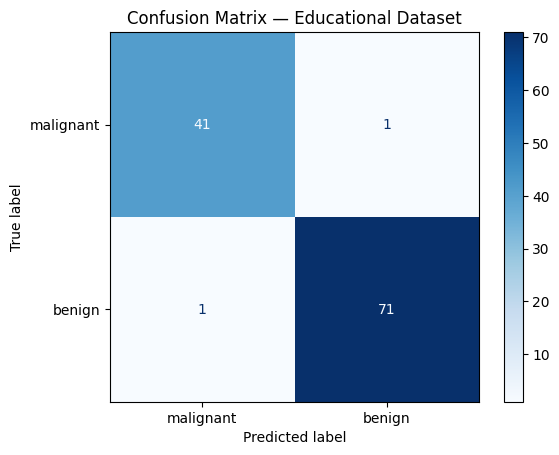

In [6]:
# Visualize the confusion matrix for the held-out test set.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["malignant", "benign"],
    cmap="Blues"
)
plt.title("Confusion Matrix — Educational Dataset")
plt.show()

## 6. Try a sample prediction
Select one example from the test set. The notebook displays the model's predicted label, the dataset label, and the model-estimated probability for the malignant class.

**Important:** This probability is not a person's real-world cancer risk and must not be interpreted as a medical result.

In [7]:
# Choose one held-out test example to inspect.
sample_position = 0
sample = X_test.iloc[[sample_position]]

# Predict the class. In this dataset, 0 = malignant and 1 = benign.
predicted_class = int(model.predict(sample)[0])
predicted_label = "malignant" if predicted_class == 0 else "benign"

# Get class probabilities; the class order is [0, 1] = [malignant, benign].
probabilities = model.predict_proba(sample)[0]
malignant_probability = float(probabilities[0])

actual_class = int(y_test.iloc[sample_position])
actual_label = "malignant" if actual_class == 0 else "benign"

print("Predicted category:", predicted_label)
print(f"Model-estimated malignant-class probability: {malignant_probability:.1%}")
print("Recorded dataset label:", actual_label)
print("\nSample measurements:")
display(sample.T.rename(columns={sample.index[0]: "Value"}))

Predicted category: malignant
Model-estimated malignant-class probability: 100.0%
Recorded dataset label: malignant

Sample measurements:


,Value
mean radius,19.550000
mean texture,28.770000
mean perimeter,133.600000
mean area,1207.000000
mean smoothness,0.092600
mean compactness,0.206300
mean concavity,0.178400
mean concave points,0.114400
mean symmetry,0.189300
mean fractal dimension,0.062320


## 7. Innovation connection and responsible AI
### Real-world innovation
AI is being studied and used to support medical image analysis, diagnostic workflows, and prioritization. For example, a 2026 *Nature Medicine* randomized controlled trial examined AI-based chest X-ray prioritization in a lung-cancer diagnostic pathway.

### How this prototype relates
This notebook demonstrates a basic classification step that can be part of a broader AI workflow. It does **not** reproduce the clinical trial or analyze raw chest X-rays.

### Limitations
- This is an educational prototype, not a medical device.
- The dataset and model may not represent other hospitals, populations, scanners, or clinical settings.
- A single train/test split is not enough to establish clinical usefulness.
- Real deployment would require external validation, privacy/security protections, human oversight, workflow evaluation, and applicable regulatory review.
- Do not upload real patient data to this notebook.

## 8. Research references
1. **UCI Machine Learning Repository — Breast Cancer Wisconsin (Diagnostic) Data Set**  
   https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
2. **scikit-learn — `load_breast_cancer` documentation**  
   https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
3. **U.S. FDA — Artificial Intelligence-Enabled Medical Devices**  
   https://www.fda.gov/medical-devices/digital-health-center-excellence/artificial-intelligence-enabled-medical-devices
4. **Nature Medicine (2026) — AI-based chest X-ray prioritization in the lung cancer diagnostic pathway: the LungIMPACT randomized controlled trial**  
   https://www.nature.com/articles/s41591-026-04253-5

---

